# **Installations**

In [ ]:
# Gymnasium (remplace OpenAI Gym)
!pip install gymnasium[all]

# PyTorch (ou TensorFlow si tu préfères)
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

# Stable-Baselines3 (pour RL moderne)
!pip install stable-baselines3

# Librairies classiques
!pip install pandas numpy scikit-learn matplotlib


  Using cached box2d-py-2.3.5.tar.gz (374 kB)
  Preparing metadata (setup.py) ... done
  Using cached swig-4.4.0-py3-none-manylinux_2_12_x86_64.manylinux2010_x86_64.whl.metadata (3.5 kB)
  Using cached mujoco-3.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (41 kB)
  Using cached array_api_compat-1.12.0-py3-none-any.whl.metadata (2.5 kB)
  Using cached numpy-2.3.5-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached glfw-2.10.0-py2.py27.py3.py30.py31.py32.py33.py34.py35.py36.py37.py38.p39.p310.p311.p312.p313-none-manylinux_2_28_x86_64.whl.metadata (5.4 kB)
  Using cached numpy-2.2.6-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
Using cached swig-4.4.0-py3-none-manylinux_2_12_x86_64.manylinux2010_x86_64.whl (1.9 MB)
Using cached array_api_compat-1.12.0-py3-none-any.whl (58 kB)
Using cached mujoco-3.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (7.0 MB)
Using cached numpy-2.2.

# **Importing Data**

In [ ]:
from google.colab import files
uploaded = files.upload()


In [ ]:
import pandas as pd

input_csv = 'CIDDS-001-external-week1.csv'
df = pd.read_csv(input_csv, parse_dates=['Date first seen'], low_memory=False)
print("Colonnes disponibles:", df.columns)

Colonnes disponibles: Index(['Date first seen', 'Duration', 'Proto', 'Src IP Addr', 'Src Pt',
       'Dst IP Addr', 'Dst Pt', 'Packets', 'Bytes', 'Flows', 'Flags', 'Tos',
       'class', 'attackType', 'attackID', 'attackDescription'],
      dtype='object')


# **EDA**

In [ ]:
# Aperçu
print(df.head())
print(df.info())
print(df.describe())

          Date first seen   Duration  Proto    Src IP Addr  Src Pt  \
0 2017-03-14 17:43:57.172  81412.697  TCP       EXT_SERVER    8082   
1 2017-03-14 17:43:57.172  81412.697  TCP    OPENSTACK_NET   56978   
2 2017-03-14 17:43:26.135  81504.787  TCP       EXT_SERVER    8082   
3 2017-03-14 17:43:26.135  81504.787  TCP    OPENSTACK_NET   56979   
4 2017-03-14 18:17:09.005  82100.692  TCP       EXT_SERVER    8082   

     Dst IP Addr   Dst Pt  Packets     Bytes  Flows   Flags  Tos   class  \
0  OPENSTACK_NET  56978.0     3057     2.1 M      1  .AP...    0  normal   
1     EXT_SERVER   8082.0     4748     2.5 M      1  .AP...    0  normal   
2  OPENSTACK_NET  56979.0     8639     9.1 M      1  .AP...    0  normal   
3     EXT_SERVER   8082.0    12024    10.3 M      1  .AP...    0  normal   
4  OPENSTACK_NET  51649.0    11012    27.2 M      1  .AP.S.    0  normal   

  attackType attackID attackDescription  
0        ---      ---               ---  
1        ---      ---               --

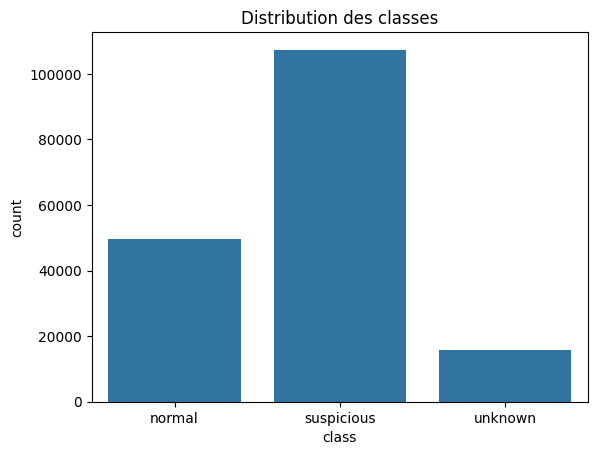

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='class', data=df)
plt.title("Distribution des classes")
plt.show()


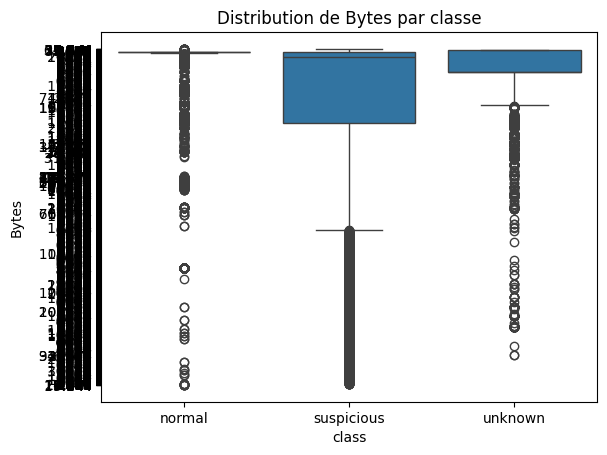

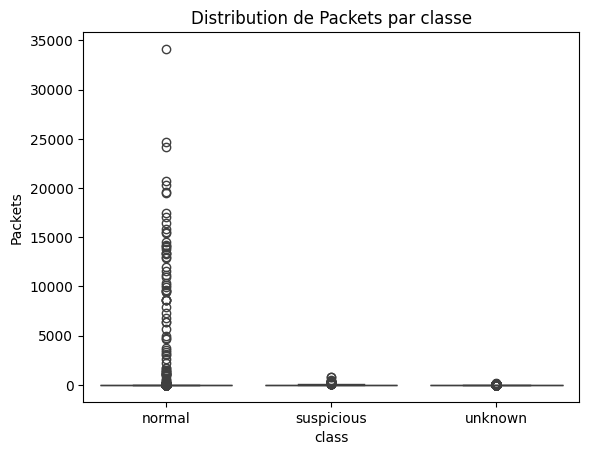

In [ ]:
sns.boxplot(x='class', y='Bytes', data=df)
plt.title("Distribution de Bytes par classe")
plt.show()

sns.boxplot(x='class', y='Packets', data=df)
plt.title("Distribution de Packets par classe")
plt.show()


# **Data preprocessing**

In [ ]:


import pandas as pd
import numpy as np
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.feature_selection import SelectKBest, chi2
import matplotlib.pyplot as plt

# -------------------------------
# Convert Columns
# -------------------------------
df['Bytes'] = pd.to_numeric(df['Bytes'], errors='coerce').fillna(0)
df['Dst Pt'] = pd.to_numeric(df['Dst Pt'], errors='coerce').fillna(0)

# -------------------------------
# Feature Engineering
# -------------------------------
df['bytes_per_packet'] = df['Bytes'] / df['Packets'].replace(0,1)

# -------------------------------
# Define numeric and categorical columns
# -------------------------------
numeric_cols = ['Duration','Src Pt','Dst Pt','Packets','Bytes','bytes_per_packet','Tos']
cat_cols = ['Proto','Flags']

# -------------------------------
# Encode categorical columns
# -------------------------------
X_cat = pd.get_dummies(df[cat_cols], drop_first=True)
# Combine numeric + categorical
X_tmp = pd.concat([df[numeric_cols], X_cat], axis=1)

# -------------------------------
# Prepare target
# -------------------------------
y_tmp = df['class']


# -------------------------------
#discretize numeric features for tabular Q-learning
# -------------------------------
def discretize_features(df, bins_config=None):
    if bins_config is None:
        bins_config = {'Duration':5, 'Packets':5, 'Bytes':5, 'bytes_per_packet':5}
    disc_df = pd.DataFrame(index=df.index)
    for col, n_bins in bins_config.items():
        est = KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy='quantile')
        disc_df[col+'_disc'] = est.fit_transform(df[[col]]).astype(int).ravel()
    return disc_df

disc_df = discretize_features(df)  # pour Q-learning tabulaire



# **Feature selection**

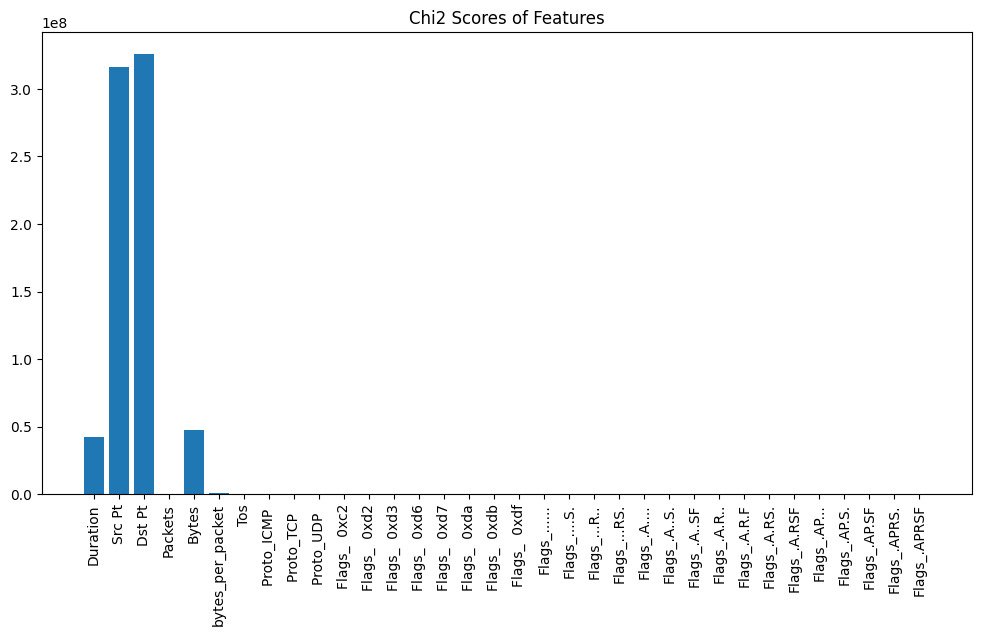

In [ ]:
from sklearn.feature_selection import SelectKBest, chi2
import matplotlib.pyplot as plt

# -------------------------------
# Make all values positive for chi2
# -------------------------------
X_positive = X_tmp - X_tmp.min().min() + 1  # chi2 requires positive values

# -------------------------------
# Feature Selection with SelectKBest (chi2)
# -------------------------------
selector = SelectKBest(chi2, k='all')  # k='all' shows scores for all features
selector.fit(X_positive, y_tmp)

# Scores
scores = selector.scores_
plt.figure(figsize=(12,6))
plt.bar(X_tmp.columns, scores)
plt.xticks(rotation=90)
plt.title("Chi2 Scores of Features")
plt.show()


In [ ]:
selector = SelectKBest(chi2, k=5)
X_selected = selector.fit_transform(X_positive, y_tmp)
selected_features = X_tmp.columns[selector.get_support()]
print("Selected features:", selected_features)

Selected features: Index(['Duration', 'Src Pt', 'Dst Pt', 'Bytes', 'bytes_per_packet'], dtype='object')


# **Unsupervised learning**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix


In [ ]:
selected_features

Index(['Duration', 'Src Pt', 'Dst Pt', 'Bytes', 'bytes_per_packet'], dtype='object')

# **Create episodes**

In [ ]:
# -------------------------------
# Create episodes for RL
# -------------------------------
def build_episodes(X, episode_len=200, stride=200):
    n = len(X)
    episodes = []
    idxs = []
    for start in range(0, n - episode_len + 1, stride):
        end = start + episode_len
        episodes.append(X[start:end])
        idxs.append((start, end))
    return np.array(episodes), np.array(idxs)

episodes, idxs = build_episodes(selected_features, episode_len=200, stride=200)

print("Number of episodes:", len(episodes))
print("Episode shape:", episodes[0].shape)

labels = df['class'].map({
    'normal': 'normal',
    'suspicious': 'attack',
    'unknown': 'attack',
    'attacker': 'attack',
    'victim': 'normal'
}).values

def build_label_episodes(y, episode_len=200, stride=200):
    lab = []
    for start in range(0, len(y) - episode_len + 1, stride):
        lab.append(y[start:start+episode_len])
    return np.array(lab)

label_episodes = build_label_episodes(labels, episode_len=200, stride=200)
print("label episodes shape",label_episodes.shape)


Number of episodes: 0


IndexError: index 0 is out of bounds for axis 0 with size 0

# **GYM ENVIRONMENT (CyberEnv)**

Un Gym Environment (environnement Gym) est un cadre standardisé pour entraîner et tester des agents de Reinforcement Learning (RL). Il provient de la bibliothèque OpenAI Gym, très utilisée dans le développement d’agents RL.
Then CyberEnv gives:

next state

reward (correct or wrong prediction)

done (episode ended or not)

In [ ]:
import gym
from gym import spaces
import numpy as np

class CyberEnv(gym.Env):
    """
    Simple cyber environment.
    - episodes: numpy array with shape (n_episodes, episode_len, n_features)
    - labels: array-like with shape (n_episodes, episode_len), values like 'attack' or 'normal'
    Action: Discrete(2) -> 0 = allow, 1 = block
    """

    metadata = {"render.modes": []}

    def __init__(self, episodes: np.ndarray, labels):
        super().__init__()
        assert episodes.ndim == 3, "episodes must be shape (n_episodes, episode_len, n_features)"
        assert episodes.shape[:2] == np.array(labels).shape[:2], "labels shape must match episodes (n_episodes, episode_len)"

        self.episodes = episodes
        self.labels = np.array(labels)
        self.n_episodes = episodes.shape[0]
        self.episode_len = episodes.shape[1]
        self.n_features = episodes.shape[2]

        # 0 = allow, 1 = block
        self.action_space = spaces.Discrete(2)
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf,
                                            shape=(self.n_features,), dtype=np.float32)

        self.current_episode = 0
        self.current_step = 0
        self.state = None

    def reset(self, episode_index: int | None = None):
        """
        Reset environment. Optionally supply episode_index to start a specific episode.
        Returns initial observation.
        """
        if episode_index is not None:
            if not (0 <= episode_index < self.n_episodes):
                raise ValueError("episode_index out of range")
            self.current_episode = int(episode_index)
        self.current_step = 0
        self.state = self.episodes[self.current_episode, self.current_step].astype(np.float32)
        return self.state

    def step(self, action):
        """
        Execute one action.
        Returns: (next_state, reward, done, info)
        """
        # validate action
        if not self.action_space.contains(action):
            raise ValueError(f"Invalid action: {action}")

        label = self.labels[self.current_episode, self.current_step]

        # reward logic:
        # action 1 = block, action 0 = allow
        if label == 'attack' and action == 1:
            reward = 1.0
        elif label == 'normal' and action == 1:
            reward = -0.5
        elif label == 'attack' and action == 0:
            reward = -1.0
        else:  # normal and allow
            reward = 0.0

        # advance step
        self.current_step += 1
        done = self.current_step >= self.episode_len

        if done:
            # move to next episode, wrap if necessary
            self.current_episode += 1
            if self.current_episode >= self.n_episodes:
                self.current_episode = 0
            # reset step to start of next episode (so environment is ready if agent calls reset next)
            self.current_step = 0
            # set state to first step of the new (or wrapped) episode
            self.state = self.episodes[self.current_episode, self.current_step].astype(np.float32)
        else:
            # not done: set next state within the same episode
            self.state = self.episodes[self.current_episode, self.current_step].astype(np.float32)

        info = {}
        return self.state, reward, done, info

    def render(self, mode='human'):
        # optional: implement visualization if you want
        pass

    def close(self):
        pass


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# **Define the DQN Model**

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

class DQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, output_dim)
        )

    def forward(self, x):
        return self.fc(x)



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# **Buffer**

In [ ]:
from collections import deque
import random

class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (np.array(states), np.array(actions), np.array(rewards),
                np.array(next_states), np.array(dones))

    def __len__(self):
        return len(self.buffer)


# **Initialize the Environment**

In [ ]:

env = CyberEnv(episodes, label_episodes)  # uses action_space Discrete(2)
print("Env ready: episodes:", env.n_episodes, "episode_len:", env.episode_len, "n_features:", env.n_features)


Env ready: episodes: 864 episode_len: 200 n_features: 34


In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cpu


# **QLearning**

In [ ]:
from collections import defaultdict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
class QLearningAgent:
    def __init__(self, env, alpha=0.1, gamma=0.9, epsilon=0.2, bins_config=None):
        self.env = env
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.Q = defaultdict(lambda: np.zeros(env.action_space.n))
        self.bins_config = bins_config
        self.feature_bins = {}

    def fit_bins(self, X):
        for i, col in enumerate(X.columns):
            n_bins = self.bins_config.get(col, 5) if self.bins_config else 5
            self.feature_bins[i] = np.linspace(X[col].min(), X[col].max(), n_bins)

    def discretize_state(self, state):
        discretized = []
        for i, value in enumerate(state):
            bins = self.feature_bins[i]
            discretized.append(int(np.digitize(value, bins) - 1))
        return tuple(discretized)

    def choose_action(self, state, episode=None):
        state_key = self.discretize_state(state)
        eps = self.epsilon
        if episode is not None:
            eps = max(0.01, self.epsilon * (0.995 ** episode))
        if np.random.random() < eps:
            return int(np.random.randint(self.env.action_space.n))
        return int(np.argmax(self.Q[state_key]))

    def update(self, state, action, reward, next_state, done):
        state_key = self.discretize_state(state)
        next_state_key = self.discretize_state(next_state)
        current_q = self.Q[state_key][action]
        target_q = reward if done else reward + self.gamma * np.max(self.Q[next_state_key])
        self.Q[state_key][action] += self.alpha * (target_q - current_q)

In [ ]:
def train_agent(env, agent, n_episodes=200):
    episode_rewards = []

    sample_state = env.reset()
    df_sample = pd.DataFrame(sample_state.reshape(1, -1), columns=[f'feat{i}' for i in range(sample_state.shape[0])])
    if agent.bins_config:
        agent.fit_bins(df_sample)

    for episode in range(n_episodes):
        state = env.reset()
        total_reward = 0
        done = False

        while not done:
            action = agent.choose_action(state, episode=episode)
            next_state, _, done, _ = env.step(action)
            label = env.labels[env.current_episode, env.current_step-1]
            correct = (label == 'attack' and action == 1) or (label == 'normal' and action == 0)
            reward = 1.0 if correct else -1.0
            agent.update(state, action, reward, next_state, done)
            state = next_state
            total_reward += reward

        episode_rewards.append(total_reward)
        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(episode_rewards[-50:])
            print(f"Épisode {episode+1}/{n_episodes} | Récompense moyenne (50 derniers): {avg_reward:.3f}")
    return episode_rewards

In [ ]:
def evaluate_agent(env, agent, n_episodes=30):
    rewards = []
    correct_actions = []
    action_counts = {0:0, 1:0}

    for episode in range(n_episodes):
        state = env.reset(episode_index=episode % env.n_episodes)
        episode_reward, episode_correct, step_count = 0, 0, 0
        done = False

        while not done:
            action = agent.choose_action(state)
            next_state, _, done, _ = env.step(action)
            state = next_state
            label = env.labels[env.current_episode, env.current_step-1]
            correct = (label == 'attack' and action == 1) or (label == 'normal' and action == 0)
            if correct:
                episode_correct += 1
            episode_reward += 1.0 if correct else -1.0
            action_counts[action] += 1
            step_count += 1

        rewards.append(episode_reward)
        correct_actions.append(episode_correct / step_count if step_count > 0 else 0)

    return rewards, correct_actions, action_counts

In [ ]:
def plot_results(rewards, correct_actions, action_counts):
    fig, axes = plt.subplots(2,2,figsize=(12,10))

    axes[0,0].plot(rewards)
    axes[0,0].set_title("Récompenses par épisode")
    axes[0,0].set_xlabel("Épisode")
    axes[0,0].set_ylabel("Récompense totale")

    axes[0,1].plot(correct_actions)
    axes[0,1].set_title("Précision par épisode")
    axes[0,1].set_xlabel("Épisode")
    axes[0,1].set_ylabel("Taux de bonnes actions")
    axes[0,1].set_ylim([0,1])

    axes[1,0].bar(['Allow (0)', 'Block (1)'], list(action_counts.values()), color=['green','red'])
    axes[1,0].set_title("Distribution des actions")
    axes[1,0].set_ylabel("Nombre d'actions")

    window = min(50, len(rewards))
    moving_avg = np.convolve(rewards, np.ones(window)/window, mode='valid')
    axes[1,1].plot(moving_avg)
    axes[1,1].set_title(f"Récompense moyenne mobile (fenêtre={window})")
    axes[1,1].set_xlabel("Épisode")
    axes[1,1].set_ylabel("Récompense moyenne")

    plt.tight_layout()
    plt.show()


In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np
import torch

def plot_confusion_matrix(env, policy_net, n_eval=20):
    y_true = []
    y_pred = []

    policy_net.eval()

    for i in range(min(n_eval, env.n_episodes)):
        state = env.reset(episode_index=i)
        done = False

        while not done:
            state_t = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)

            with torch.no_grad():
                action = int(torch.argmax(policy_net(state_t), dim=1).item())

            next_state, reward, done, info = env.step(action)

            # Vrai label
            label = env.label_episodes[env.current_episode, env.current_step]
            true_class = 1 if label in ["attack", "attacker"] else 0

            # Prédiction = action du DQN
            pred_class = action

            y_true.append(true_class)
            y_pred.append(pred_class)

            state = next_state

    cm = confusion_matrix(y_true, y_pred)
    return cm


Création de l'environnement...
Environnement créé: 100 épisodes, 200 steps par épisode

Création de l'agent...
Agent créé avec 0 états initiaux

Début de l'entraînement...
Épisode 50/200 | Récompense moyenne (50 derniers): 61.760
Épisode 100/200 | Récompense moyenne (50 derniers): 82.320
Épisode 150/200 | Récompense moyenne (50 derniers): 66.360
Épisode 200/200 | Récompense moyenne (50 derniers): 85.520

Évaluation de l'agent...

=== RÉSULTATS FINAUX ===
Récompense moyenne: 21.067
Précision moyenne: 55.27%
Actions Allow: 3670, Actions Block: 2330
Total Q-table size: 11 états uniques


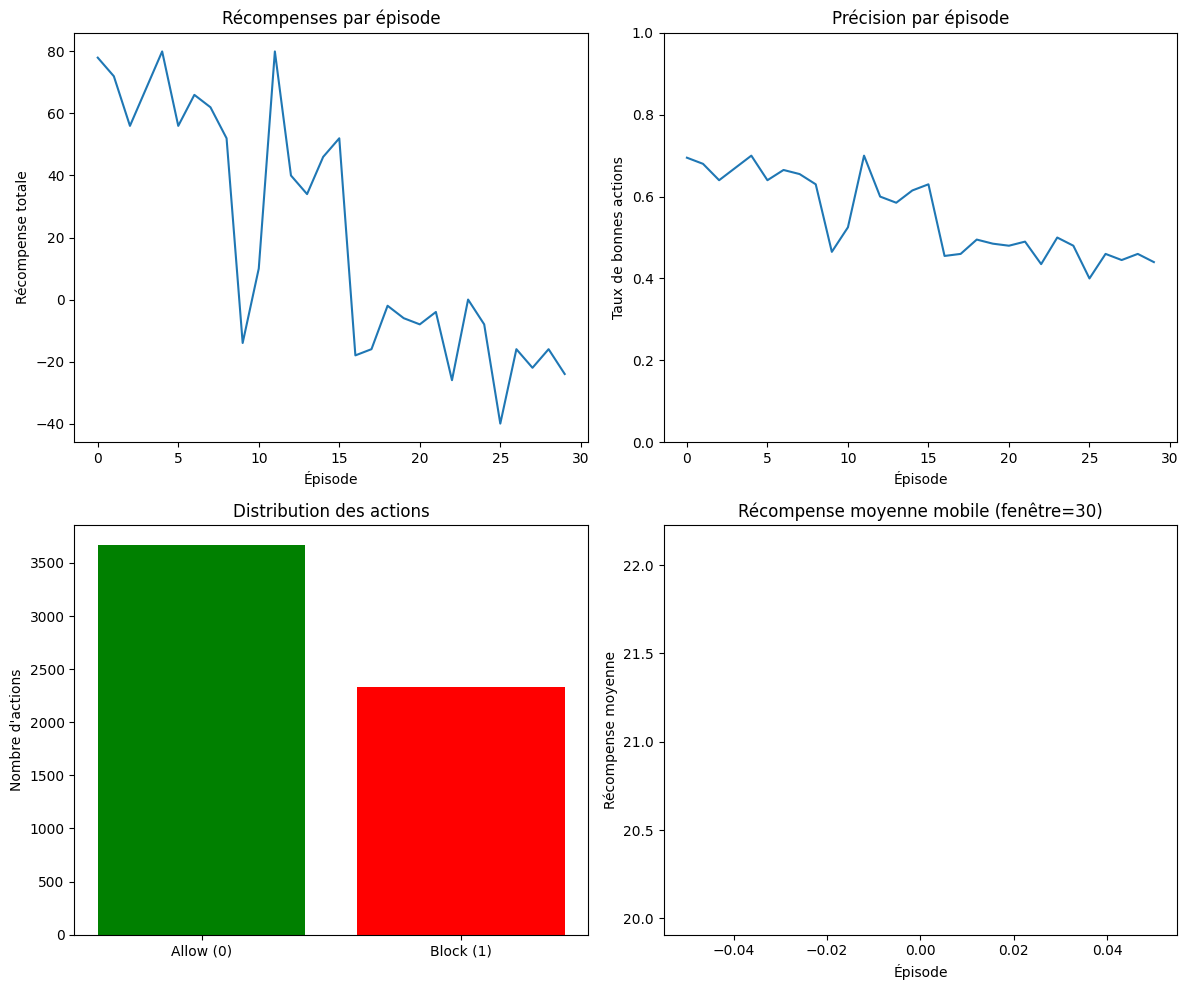


=== EXEMPLE D'INFERENCE ===
État initial (premières 5 features): [  13.541   22.    1381.      18.    2985.   ]
Step 0: Label=ATTACK, Action=BLOCK
  Récompense: 1.0
Step 1: Label=ATTACK, Action=BLOCK
  Récompense: 1.0
Step 2: Label=ATTACK, Action=BLOCK
  Récompense: 1.0
Step 3: Label=ATTACK, Action=BLOCK
  Récompense: 1.0
Step 4: Label=ATTACK, Action=ALLOW
  Récompense: -1.0


In [ ]:
print("Création de l'environnement...")
env = CyberEnv(episodes[:100], label_episodes[:100])
print(f"Environnement créé: {env.n_episodes} épisodes, {env.episode_len} steps par épisode")

print("\nCréation de l'agent...")
bins_config = {f'feat{i}':5 for i in range(episodes.shape[2])}
agent = QLearningAgent(env, alpha=0.1, gamma=0.9, epsilon=0.2, bins_config=bins_config)
print(f"Agent créé avec {len(agent.Q)} états initiaux")

print("\nDébut de l'entraînement...")
training_rewards = train_agent(env, agent, n_episodes=200)

print("\nÉvaluation de l'agent...")
test_env = CyberEnv(episodes[100:150], label_episodes[100:150])
evaluation_rewards, accuracy_rates, action_dist = evaluate_agent(test_env, agent, n_episodes=30)

print(f"\n=== RÉSULTATS FINAUX ===")
print(f"Récompense moyenne: {np.mean(evaluation_rewards):.3f}")
print(f"Précision moyenne: {np.mean(accuracy_rates)*100:.2f}%")
print(f"Actions Allow: {action_dist[0]}, Actions Block: {action_dist[1]}")
print(f"Total Q-table size: {len(agent.Q)} états uniques")

plot_results(evaluation_rewards, accuracy_rates, action_dist)

print("\n=== EXEMPLE D'INFERENCE ===")
if len(episodes) > 151 and len(label_episodes) > 151:
    test_env = CyberEnv(episodes[150:151], label_episodes[150:151])
    state = test_env.reset()
    print(f"État initial (premières 5 features): {state[:5]}")

    for step in range(min(5, test_env.episode_len)):
        action = agent.choose_action(state)
        label = test_env.labels[test_env.current_episode, test_env.current_step]
        action_str = "BLOCK" if action == 1 else "ALLOW"
        label_str = "ATTACK" if label == 'attack' else "NORMAL"
        print(f"Step {step}: Label={label_str}, Action={action_str}")
        state, reward, done, _ = test_env.step(action)
        print(f"  Récompense: {reward}")
        if done:
            break
else:
    print("Pas assez d'épisodes pour l'exemple d'inférence")



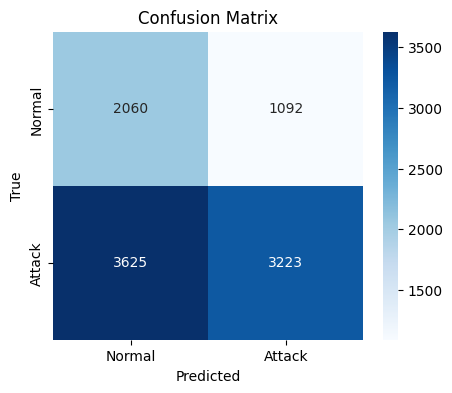

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_true = []
y_pred = []

test_env = CyberEnv(episodes[100:150], label_episodes[100:150])

for ep in range(test_env.n_episodes):
    state = test_env.reset(episode_index=ep)
    done = False

    while not done:
        action = agent.choose_action(state)

        # vrai label
        label = test_env.labels[test_env.current_episode, test_env.current_step]
        true_class = 1 if label in ["attack", "attacker"] else 0

        # prédiction de l’agent
        pred_class = action  # 1 = BLOCK → attack

        y_true.append(true_class)
        y_pred.append(pred_class)

        state, reward, done, _ = test_env.step(action)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Attack"],
            yticklabels=["Normal", "Attack"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()



**Define the DQN Algorithm Parameters**

In [ ]:

# ---------------------------------------
# Environment dimensions
# ---------------------------------------

input_dim = env.n_features
# Number of input features per state (depends on your selected features)

n_actions = env.action_space.n
# Number of possible actions (here: 2 → allow or block)


# ---------------------------------------
# Neural network architecture
# ---------------------------------------

hidden = [128, 128]
# Size of hidden layers in the DQN network
# Larger values = more learning capacity but slower training


# ---------------------------------------
# Optimizer / learning parameters
# ---------------------------------------

lr = 1e-4
# Learning rate for Adam optimizer
# Smaller = more stable but slower learning
# Larger = faster but may diverge


gamma = 0.99
# Discount factor: how much future rewards matter
# 1.0 → care mostly about long-term reward
# 0.0 → care only about immediate reward


# ---------------------------------------
# Replay buffer and batch training
# ---------------------------------------

batch_size = 64
# Number of samples used per gradient update

buffer_capacity = 1000000
# Max number of transitions stored in replay buffer
# Bigger = more diverse experience, better learning, but more memory

min_buffer_size = 6000
# Start training only after buffer has this many stored transitions
# Prevents early training on tiny/biased samples


# ---------------------------------------
# Training length
# ---------------------------------------

total_episodes = 765
# How many episodes to train the agent on


target_update_every = 5
# Update target network every 5 episodes
# More frequent updates → less stable learning
# Less frequent → more stable but slower


# ---------------------------------------
# Exploration vs Exploitation
# ---------------------------------------

epsilon_start = 1.0
# Initial exploration probability
# 1.0 = 100% random actions at the beginning

epsilon_final = 0.01
# Minimum exploration value
# Agent will still take 1% random actions even after training

epsilon_decay_episodes = 100.0
# Number of episodes to decay epsilon from 1.0 → 0.01 linearly
# Smaller = decay faster → agent exploits earlier
# Larger = explore more before exploiting


# ---------------------------------------
# Episode length
# ---------------------------------------

max_steps = env.episode_len
# Maximum steps per episode (200 in your case)
# Agent moves through 200 states before episode ends


# **Define the Loss Function and Optimizer**

In [ ]:

policy_net = DQN(input_dim, n_actions).to(device)
target_net = DQN(input_dim, n_actions).to(device)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

optimizer = optim.Adam(policy_net.parameters(), lr=lr)
mse_loss = nn.MSELoss()

replay = ReplayBuffer(capacity=buffer_capacity)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# epsilon schedule
def get_epsilon(ep):
    if ep >= epsilon_decay_episodes:
        return epsilon_final
    return epsilon_start - (epsilon_start - epsilon_final) * (ep / epsilon_decay_episodes)

# utility to select action
def select_action(state, epsilon):
    if random.random() < epsilon:
        return random.randrange(n_actions)
    state_t = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
    with torch.no_grad():
        qvals = policy_net(state_t)
        return int(torch.argmax(qvals, dim=1).item())



# **Training the DQN**

In [ ]:

episode_rewards = []
losses = []
steps_done = 0

for ep in range(total_episodes):
    state = env.reset()
    ep_reward = 0.0
    eps = get_epsilon(ep)

    for t in range(max_steps):
        action = select_action(state, eps)
        next_state, reward, done, info = env.step(action)
        replay.push(state, action, reward, next_state, done)
        state = next_state
        ep_reward += reward
        steps_done += 1

        # Learn
        if len(replay) >= min_buffer_size:
            states_b, actions_b, rewards_b, next_states_b, dones_b = replay.sample(batch_size)

            states_b = torch.tensor(states_b, dtype=torch.float32, device=device)
            next_states_b = torch.tensor(next_states_b, dtype=torch.float32, device=device)
            actions_b = torch.tensor(actions_b, dtype=torch.int64, device=device).unsqueeze(1)
            rewards_b = torch.tensor(rewards_b, dtype=torch.float32, device=device)
            dones_b = torch.tensor(dones_b, dtype=torch.float32, device=device)

            # Current Q values
            q_values = policy_net(states_b).gather(1, actions_b).squeeze(1)  # shape (batch,)

            # Next Q values from target
            with torch.no_grad():
                next_q_values = target_net(next_states_b).max(dim=1)[0]

            # Compute target
            target = rewards_b + gamma * next_q_values * (1.0 - dones_b)

            loss = mse_loss(q_values, target)

            optimizer.zero_grad()
            loss.backward()
            # optional: gradient clipping
            torch.nn.utils.clip_grad_norm_(policy_net.parameters(), 10.0)
            optimizer.step()

            losses.append(loss.item())

        if done:
            break

    episode_rewards.append(ep_reward)

    # Update target network periodically
    if (ep + 1) % target_update_every == 0:
        target_net.load_state_dict(policy_net.state_dict())

    # Logging
    if (ep + 1) % 10 == 0 or ep == 0:
        recent_avg = np.mean(episode_rewards[-10:]) if len(episode_rewards) >= 10 else np.mean(episode_rewards)
        recent_loss = np.mean(losses[-100:]) if losses else 0.0
        print(f"Episode {ep+1}/{total_episodes} | eps {eps:.3f} | recent_avg_reward {recent_avg:.3f} | loss {recent_loss:.5f} | buffer {len(replay)}")


Episode 1/765 | eps 1.000 | recent_avg_reward -13.000 | loss 0.00000 | buffer 200
Episode 10/765 | eps 0.911 | recent_avg_reward -5.550 | loss 0.00000 | buffer 2000
Episode 20/765 | eps 0.812 | recent_avg_reward 5.950 | loss 0.00000 | buffer 4000
Episode 30/765 | eps 0.713 | recent_avg_reward 0.050 | loss 31761.84766 | buffer 6000
Episode 40/765 | eps 0.614 | recent_avg_reward -24.150 | loss 18139.79849 | buffer 8000
Episode 50/765 | eps 0.515 | recent_avg_reward -17.900 | loss 18602.09747 | buffer 10000
Episode 60/765 | eps 0.416 | recent_avg_reward -16.950 | loss 10827.90844 | buffer 12000
Episode 70/765 | eps 0.317 | recent_avg_reward -14.150 | loss 21364.93750 | buffer 14000
Episode 80/765 | eps 0.218 | recent_avg_reward -3.550 | loss 12456.78849 | buffer 16000
Episode 90/765 | eps 0.119 | recent_avg_reward 5.150 | loss 7596.06992 | buffer 18000
Episode 100/765 | eps 0.020 | recent_avg_reward 27.300 | loss 7614.62841 | buffer 20000
Episode 110/765 | eps 0.010 | recent_avg_reward 14

In [ ]:
s, done = env.reset(), False
action = policy_net(torch.tensor(s, dtype=torch.float32).to(device)).argmax().item()
next_s, reward, done, _ = env.step(action)
print("Action:", action, "Reward:", reward, "Label:", label_episodes[env.current_episode, env.current_step])


Action: 1 Reward: 1.0 Label: attack


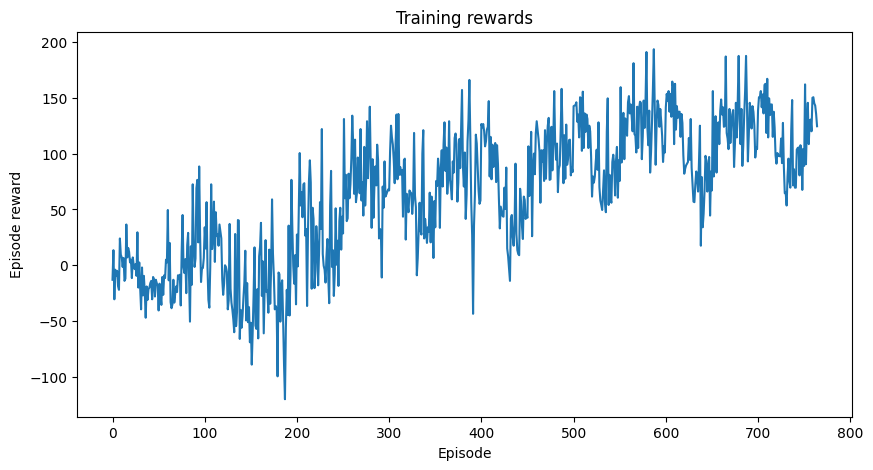

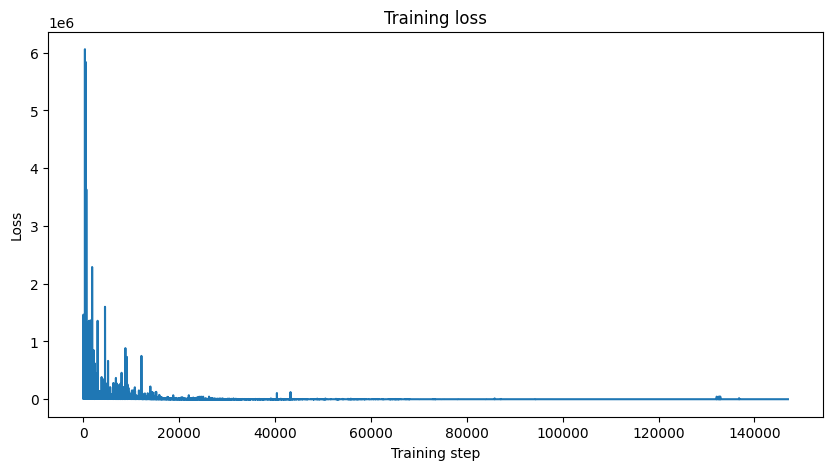

In [ ]:
# -------------------------------
# Plots
# -------------------------------
plt.figure(figsize=(10,5))
plt.plot(episode_rewards)
plt.xlabel("Episode")
plt.ylabel("Episode reward")
plt.title("Training rewards")
plt.show()

if losses:
    plt.figure(figsize=(10,5))
    plt.plot(losses)
    plt.xlabel("Training step")
    plt.ylabel("Loss")
    plt.title("Training loss")
    plt.show()


# **Evaluating the Trained DQN**

In [ ]:

def evaluate_policy(env, policy_net, n_eval=20):
    rewards = []
    for i in range(min(n_eval, env.n_episodes)):
        obs = env.reset(episode_index=i)
        done = False
        tot = 0.0
        while not done:
            with torch.no_grad():
                st = torch.tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)
                action = int(torch.argmax(policy_net(st), dim=1).item())
            obs, r, done, info = env.step(action)
            tot += r
        rewards.append(tot)
    return np.array(rewards)

eval_rewards = evaluate_policy(env, policy_net, n_eval=20)
print("Evaluation rewards (mean):", eval_rewards.mean(), "std:", eval_rewards.std())
print("First eval rewards:", eval_rewards[:10])


Evaluation rewards (mean): 145.9 std: 15.33182963641326
First eval rewards: [149.5 158.  154.  162.  147.5 160.  141.  165.  166.  127. ]


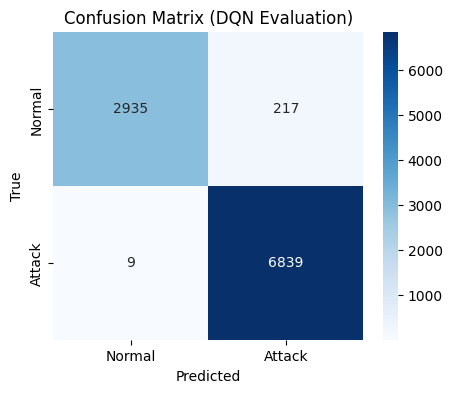

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_true = []
y_pred = []

policy_net.eval()

for ep in range(test_env.n_episodes):
    state = test_env.reset(episode_index=ep)
    done = False

    while not done:
        state_t = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
        with torch.no_grad():
            action = torch.argmax(policy_net(state_t), dim=1).item()

        # true label
        label = test_env.labels[test_env.current_episode,
                                         test_env.current_step]
        true_class = 1 if label in ["attack", "attacker"] else 0

        pred_class = action  # 1 = BLOCK → attack

        y_true.append(true_class)
        y_pred.append(pred_class)

        state, reward, done, _ = test_env.step(action)


cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Attack"],
            yticklabels=["Normal", "Attack"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (DQN Evaluation)")
plt.show()
